Задание 1. Написать функцию, принимающую в качестве аргумента число N –
размерность квадратной матрицы А. Используя стандартные функции NumPy для
формирования матриц специального вида (ones, zeros, diag, linspace, arange и пр.),
создать матрицу А, имеющую указанную в варианте структуру. Нельзя
использовать циклы, генераторы и пр. Полученную матрицу записать в файл
(savetxt или др. функции).

Вариант 21.
 5 0 0 0 0 0  0
-5 4 0 0 0 0  0
 5 0 3 0 0 0  0
-5 5 0 2 0 0  0
 5 0 5 0 1 0  0
-5 0 0 5 0 0  0
 5 0 0 0 5 0 -1

In [9]:
import numpy as np

def createMatrix(N):
    A = np.zeros((N, N))
    diagonal_values = np.arange(N - 2, N - 2 - N, -1)
    down_diagonal_position = N // 2 - 1
    down_diagonal_values = np.full(N - down_diagonal_position, N - 2)
    A += np.diag(down_diagonal_values, -down_diagonal_position)
    A[N // 2 - 1, 0] = 0       
    A[:, 0] += ((N - 2) * (-1)**np.arange(N))
    np.fill_diagonal(A, diagonal_values)
    np.savetxt("Saved_Matrix", A, '%d')
    #return A

N = 10
#print(createMatrix(N))
createMatrix(N)

Задание 2. Написать функцию, которая читает из файла матрицу А, созданную
в задании 1, и проводит с ней указанные в варианте действия, используя модуль
numpy.linalg.
Вариант 21. Найти октаэдрическую норму матрицы А. Найти собственные
значения и собственные векторы матрицы А. Вывести октаэдрическую норму
собственного вектора, соответствующего минимальному по модулю собственному
значению.

In [3]:
import numpy as np

def octNormFoo(A):
    result = np.linalg.norm(A, ord = 1)
    return result

def eigValVecFoo(A):
    eig_values, eig_vectors = np.linalg.eig(A)
    return eig_values, eig_vectors

def printAbsMinOctNorm(A, eig_values, eig_vectors):
    min_abs_eig_value_idx = np.argmin(np.abs(eig_values))
    #min_abs_eig_value = eig_values[mib_abs_eig_value_idx]
    res_vector = eig_vectors[:, min_abs_eig_value_idx]
    result = np.linalg.norm(res_vector, ord = 1)
    return result

filename = "Saved_Matrix"
A = np.loadtxt(filename)
oct_norm = octNormFoo(A)
print(oct_norm, '\n')
eig_values, eig_vectors = eigValVecFoo(A)
print(eig_values, '\n')
print(eig_vectors, '\n')
min_oct_norm = printAbsMinOctNorm(A, eig_values, eig_vectors)
print(min_oct_norm, '\n')

35.0 

[-1.  0.  2.  4.  1.  3.  5.] 

[[ 0.          0.          0.          0.          0.          0.
   0.05847518]
 [ 0.          0.          0.          0.24242424  0.          0.
  -0.29237588]
 [ 0.          0.          0.          0.          0.          0.24242424
   0.14618794]
 [ 0.          0.          0.37139068  0.60606061  0.          0.
  -0.58475177]
 [ 0.          0.          0.          0.          0.37139068  0.60606061
   0.2558289 ]
 [ 0.          1.          0.92847669  0.75757576  0.          0.
  -0.64322695]
 [ 1.          0.          0.          0.          0.92847669  0.75757576
   0.26192006]] 

1.0 



Задание 3. Создать 2 функции, вычисляющие приведенную ниже сумму; z –
аргумент функции, число
N – необязательный аргумент, равный по умолчанию 10.
Первая функция должна вычислять сумму, используя циклы, вторая – без
использования циклов (а также не используя символьные вычисления, генераторы
и т.п.). Сравнить время выполнения первой и второй функции.
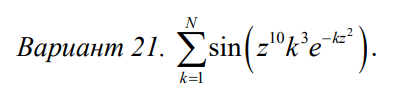

In [8]:
import numpy as np
import time

def loopSum(z, N = 10):
    start_time = time.perf_counter()
    result_sum = 0
    for k in range(1, N + 1):
        result_sum += np.sin((z ** 10) * (k ** 3) * np.exp(-k * (z ** 2)))
    end_time = time.perf_counter()
    res_time = end_time - start_time
    return result_sum, res_time

def funcSum(z, N = 10):
    start_time = time.perf_counter()
    k = np.arange(1, N + 1)
    result_sum = np.sum(np.sin((z ** 10) * (k ** 3) * np.exp(-k * (z ** 2))))
    end_time = time.perf_counter()
    res_time = end_time - start_time
    return result_sum, res_time

z = 1
first_sum, first_time = loopSum(z, 10000)
print(first_sum, first_time)
second_sum, second_time = funcSum(z, 10000)
print(second_sum, second_time)

5.051032806223603 0.07763410000006843
5.051032806223606 0.0014246000009734416


<function matplotlib.pyplot.show(close=None, block=None)>

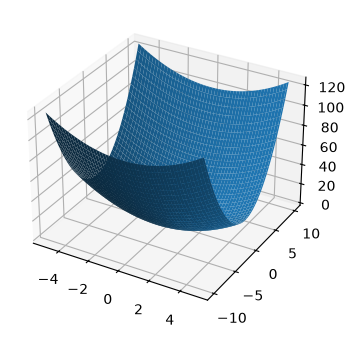

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

x = np.linspace(-5, 5, 100)
y = np.linspace(-10, 10, 200)
X, Y = np.meshgrid(x, y)
Z = X ** 2 + Y ** 2
fig = plt.figure(figsize = (4, 8))
ax = fig.add_subplot(111, projection = '3d')
surf = ax.plot_surface(X, Y, Z)
plt.show